In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import wfdb # type: ignore
import sleepecg
import re
import os
import pickle
from processing import split_segment, signal_selection_algorithm
from tqdm import tqdm

# import logging

# logging.basicConfig(level=logging.INFO, format='%(threadName)s: %(message)s')

# database_name = 'mimic4wdb/0.1.0'
database_name = 'mimic3wdb/1.0'

In [2]:
# # each subject may be associated with multiple records
# subjects = wfdb.get_record_list(database_name)
# print(f"The '{database_name}' database contains data from {len(subjects)} subjects")

# # set max number of records to load
# max_records_to_load = 1000

# # iterate the subjects to get a list of records
# records = []
# # for subject in subjects:
# # 	studies = wfdb.get_record_list(f'{database_name}/{subject}')
# # 	for study in studies:
# # 		records.append(Path(f'{subject}{study}'))
# 	# stop if we've loaded enough records
# 	# if len(records) >= max_records_to_load:
# 	# 	print("Reached maximum required number of records.")
# 	# 	break
    
# def get_studies(subject):
#     studies = wfdb.get_record_list(f'{database_name}/{subject}')
#     return [Path(f'{subject}{study}') for study in studies]

# with concurrent.futures.ThreadPoolExecutor(max_workers=20) as executor:
#     futures = [executor.submit(get_studies, subject) for subject in subjects]
#     for future in concurrent.futures.as_completed(futures):
#         records.extend(future.result())
        
# print(f"Loaded {len(records)} records from the '{database_name}' database.")

In [3]:
# with open("data/mimic3_records.pkl", "wb") as file:
#     pickle.dump(records, file)
    
with open("data/mimic3_records.pkl", "rb") as file:
    records = pickle.load(file)
    
# records

In [4]:
required_sigs = ['II', 'ABP', 'PLETH']
req_seg_duration = 5  # seconds
matching_recs = {'subject_id': [], 'seg_name': [], 'path': [], 'length': []}

# logging.basicConfig(filename='processing.log', level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

def process_record(record):
	record_dir = f'{database_name}/{record.parent}'.replace('\\', '/')
	record_name = record.name

	if not re.match(r'^\d+$', record_name):
		return None

	# logging.info(f'Record: {record}, ID:{os.getpid()}')
	print(f'Record: {record}, ID:{os.getpid()}', end="", flush=True)
	print(' (reading data)', end="", flush=True)

	try:
		record_metadata = wfdb.rdheader(record_name=f'{record_name}',
										pn_dir=record_dir,
										rd_segments=True
										)
	except:
		print('  (error)')
		return None

	record_present = record_metadata.sig_name
	if all(x in record_present for x in required_sigs):
		for segment_name in record_metadata.seg_name:
			if re.match(r'^[\d_]+$', segment_name) and not re.search(r'[a-zA-Z]', segment_name) and segment_name != '~':
				print(f' - Segment: {segment_name}', end="", flush=True)

				try:
					segment_metadata = wfdb.rdheader(record_name=f'{segment_name}', pn_dir=record_dir)
				except:
					print('   (error)')
					continue

				seg_length = segment_metadata.sig_len / (segment_metadata.fs)

				if seg_length < req_seg_duration:
					print(f' (too short at {seg_length / 60:.1f} mins)')
					continue

				sigs_present = segment_metadata.sig_name
				if all(x in sigs_present for x in required_sigs):
					print(' (met requirements)')
					return {
						'subject_id': record_name,
						'seg_name': segment_name,
						'path': f'{record.parent}/{segment_name}',
						'length': seg_length
					}
				else:
					print(' (long enough, but missing signal(s))')
	else:
		print(' (missing signal(s))')
	return None

from joblib import Parallel, delayed
results = Parallel(n_jobs=-1, verbose=100)(delayed(process_record)(record) for record in records)
results

for result in results:
	# result = process_record(record)
	if result:
		matching_recs['subject_id'].append(result['subject_id'])
		matching_recs['seg_name'].append(result['seg_name'])
		matching_recs['path'].append(result['path'])
		matching_recs['length'].append(result['length'])

print(f"A total of {len(matching_recs['path'])} records met the requirements:")

df_matching_recs = pd.DataFrame(data=matching_recs)
df_matching_recs.to_csv('data/matching_records_mimic3.csv', index=False)

In [ ]:
from joblib import Parallel, delayed
count = 0
final_records = []

def process_row(row):
    records = []
    try:
        print(f'For {row["seg_name"]}')
        valid_segments, fs = split_segment(f'{row["path"]}')
        print(f'- The amount of remaining segment groups after splitting: {len(valid_segments)}')
        valid_records = signal_selection_algorithm(valid_segments, fs)
        print(f'- The amount of final remaining segment groups after SQI: {len(valid_records)}')

        for r in range(len(valid_records)):
            records.append({
                'seg_name': f"{row['seg_name']}_{str(r)}",
                'ecg': valid_records[r]['ECG'],
                'ppg': valid_records[r]['PPG'],
                'true_sbp': valid_records[r]['true_sbp'],
                'true_dbp': valid_records[r]['true_dbp']
            })
    except Exception as e:
        print(f'Error processing {row["seg_name"]}: {e}')
    return records

# Read the CSV file in chunks to manage memory usage
for chunk in pd.read_csv('data/matching_records_mimic3.csv', chunksize=1000):
    results = Parallel(n_jobs=-1)(
        delayed(process_row)(row) for index, row in chunk.iterrows()
    )
    for res in results:
        final_records.extend(res)
        count += len(res)

count = 0
chunk_number = 8  # To keep track of chunk numbers

for chunk in pd.read_csv('data/matching_records_mimic3.csv', chunksize=1000, skiprows=range(1, 8001)):
    final_records = []  # Reset final_records for each chunk
    for index, row in tqdm(chunk.iterrows(), total=chunk.shape[0], desc=f'Processing Chunk {chunk_number}', leave=False):
        try:
            # print(f'For {row["seg_name"]} - {count}', flush=True)
            valid_segments, fs = split_segment(f'{row["path"]}')
            # print(f'- The amount of remaining segment groups after splitting: {len(valid_segments)}', flush=True)
            valid_records = signal_selection_algorithm(valid_segments, fs)
            # print(f'- The amount of final remaining segment groups after SQI: {len(valid_records)}', flush=True)
            count += len(valid_records)

            for r in range(len(valid_records)):
                final_records.append({
                    'subject_id': f"{row['seg_name']}",
                    'seg_name': f"{row['seg_name']}_{str(r)}",
                    'ecg': valid_records[r]['ECG'],
                    'ppg': valid_records[r]['PPG'],
                    'true_sbp': valid_records[r]['true_sbp'],
                    'true_dbp': valid_records[r]['true_dbp']
                })
        except Exception as e:
            print('Error:', e, flush=True)
            continue

    # Save the final_records for this chunk
    np.save(f'data/final_records_mimic3_chunk_{chunk_number}.npy', final_records)
    chunk_number += 1  # Increment the chunk number

Processing Chunk 8:   0%|          | 0/1000 [00:00<?, ?it/s]

Processing Chunk 8:   0%|          | 1/1000 [00:02<39:40,  2.38s/it]c:\Users\user\Documents\Python Scripts\mimic4_abp_hybridnn\processing.py:99: RuntimeWarning: divide by zero encountered in scalar divide
  hr = 60 / np.mean(peak_intervals) if len(peak_intervals) > 0 else np.nan
Processing Chunk 8:   1%|▏         | 13/1000 [02:01<1:18:38,  4.78s/it]

Error: index 0 is out of bounds for axis 0 with size 0


Processing Chunk 8:   4%|▍         | 42/1000 [18:42<17:14:08, 64.77s/it]

Error: index 0 is out of bounds for axis 0 with size 0


...

Error: arrays used as indices must be of integer (or boolean) type


Processing Chunk 10:  94%|█████████▍| 755/801 [4:43:21<03:54,  5.11s/it]  

Error: index 0 is out of bounds for axis 0 with size 0


Processing Chunk 10:  96%|█████████▌| 765/801 [4:45:01<07:54, 13.18s/it]

Error: index 0 is out of bounds for axis 0 with size 0


---

In [3]:
import numpy as np
import pandas as pd
import glob
import pyarrow as pa
import pyarrow.parquet as pq
import os

# Define the directory and file pattern to match all .npy files for chunks
file_pattern = 'data/final_records_mimic3_chunk_*.npy'
parquet_file = 'data/final_records_mimic3_all.parquet'

# Check if the Parquet file exists
parquet_exists = os.path.exists(parquet_file)

# Process each .npy file
for file in sorted(glob.glob(file_pattern)):
    # Load the .npy file
    chunk_data = np.load(file, allow_pickle=True)
    df = pd.DataFrame(chunk_data)  # Convert to DataFrame

    # Convert to a Parquet table
    table = pa.Table.from_pandas(df)

    # Write or append to the Parquet file
    if not parquet_exists:
        pq.write_table(table, parquet_file)  # Create new file on first chunk
        parquet_exists = True  # Set flag to indicate file now exists
    else:
        # Append to the existing Parquet file
        with pq.ParquetWriter(parquet_file, table.schema, use_dictionary=True) as writer:
            writer.write_table(table)

    del chunk_data, df  # Free up memory


In [9]:
import pandas as pd

# Load the Parquet file
parquet_file = 'data/final_records_mimic3_all.parquet'
df = pd.read_parquet(parquet_file)

# Expand the dictionary data in the single column into a DataFrame
df_expanded = pd.json_normalize(df[0])  # This flattens the dictionary structure

# Add the 'subject_id' column by extracting from 'seg_name'
if 'seg_name' in df_expanded.columns:
    df_expanded['subject_id'] = df_expanded['seg_name'].apply(lambda x: x.split('_')[0])
    # Save the modified DataFrame back to a new Parquet file
    df_expanded.to_parquet('data/final_records_mimic3_all_with_id.parquet')
    print("Data saved with 'subject_id' column.")
else:
    print("Column 'seg_name' not found in the expanded DataFrame.")


Data saved with 'subject_id' column.


In [28]:
# format and print first five records
first_five_records = [str(x).replace('\\', '/') for x in records[0:5]]
first_five_records = "\n - ".join(first_five_records)
print(f"First five records: \n - {first_five_records}")

First five records: 
 - 30/3000031/3000031n
 - 30/3000051/3000051
 - 30/3000051/3000051_0001
 - 30/3000051/3000051_0002
 - 30/3000051/3000051_0003


In [10]:
# Specify the 4th record (note, in Python indexing begins at 0)
idx = 2
record = records[idx]
record_dir = f'{database_name}/{record.parent}'.replace('\\', '/')
print("PhysioNet directory specified for record: {}".format(record_dir))

record_name = record.name
print("Record name: {}".format(record_name))

record_data = wfdb.rdheader(record_name, rd_segments=True, pn_dir=record_dir)
# segment_data = wfdb.rdrecord('3000063_0006', pn_dir=f'{database_name}/30/3000063')

# for sig_no in range(len(segment_data.sig_name)):
# 	if "PLETH" in segment_data.sig_name[sig_no]:
# 		ppg_sig_no = sig_no
# 	if "ABP" in segment_data.sig_name[sig_no]:
# 		abp_sig_no = sig_no
# 	if "II" in segment_data.sig_name[sig_no]:
# 			ecg_sig_no = sig_no
# ppg = segment_data.p_signal[:, ppg_sig_no]
# abp = segment_data.p_signal[:, abp_sig_no]
# ecg = segment_data.p_signal[:, ecg_sig_no]
# fs = segment_data.fs
# print(ppg)
print(f"Done: metadata loaded for record '{record_name}'")
display(record_data.__dict__)

# print(f"- Number of signals: {record_data.n_sig}".format())
# print(f"- Duration: {record_data.sig_len/(record_data.fs*60*60):.1f} hours") 
# print(f"- Base sampling frequency: {record_data.fs} Hz")

# segments = record_data.seg_name
# print(f"The {len(segments)} segments from record {record_name} are:\n{segments}")

PhysioNet directory specified for record: mimic3wdb/1.0/30/3000051
Record name: 3000051_0001


MainThread: GET https://physionet.org/files/mimic3wdb/1.0/30/3000063/3000063_0006.hea: 200 0-205/205
MainThread: GET https://physionet.org/files/mimic3wdb/1.0/30/3000063/3000063_0006.dat: 206 0-2226045/2226045


[0.5254902  0.52941176 0.52941176 ... 0.54901961 0.55686275 0.56862745]
Done: metadata loaded for record '3000051_0001'


{'record_name': '3000063_0006',
 'n_sig': 3,
 'fs': 125,
 'counter_freq': None,
 'base_counter': None,
 'sig_len': 742015,
 'base_time': datetime.time(21, 17, 59),
 'base_date': None,
 'comments': [],
 'sig_name': ['II', 'ABP', 'PLETH'],
 'p_signal': array([[-6.29921260e-02,             nan,  5.25490196e-01],
        [-4.72440945e-02,             nan,  5.29411765e-01],
        [-6.29921260e-02,             nan,  5.29411765e-01],
        ...,
        [ 6.29921260e-02,  5.90623154e+01,  5.49019608e-01],
        [ 9.44881890e-02,  6.28123037e+01,  5.56862745e-01],
        [ 1.10236220e-01,  6.84372861e+01,  5.68627451e-01]]),
 'd_signal': None,
 'e_p_signal': None,
 'e_d_signal': None,
 'file_name': ['3000063_0006.dat', '3000063_0006.dat', '3000063_0006.dat'],
 'fmt': ['80', '80', '80'],
 'samps_per_frame': [1, 1, 1],
 'skew': [None, None, None],
 'byte_offset': [None, None, None],
 'adc_gain': [127.0, 1.06667, 255.0],
 'baseline': [-64, -109, -128],
 'units': ['mV', 'mmHg', 'NU'],
 'adc_

Header metadata loaded for: 
- the segment '3000003_0001'
- for subject 'mimic3wdb\1.0\30'

This segment contains the following signals: ['II', 'V']
The signals are measured in units of: ['mV', 'mV']
The signals have a base sampling frequency of 125.0 Hz
and they last for 2.3 minutes
Extracted the PPG signal from column 0 of the matrix of waveform data.


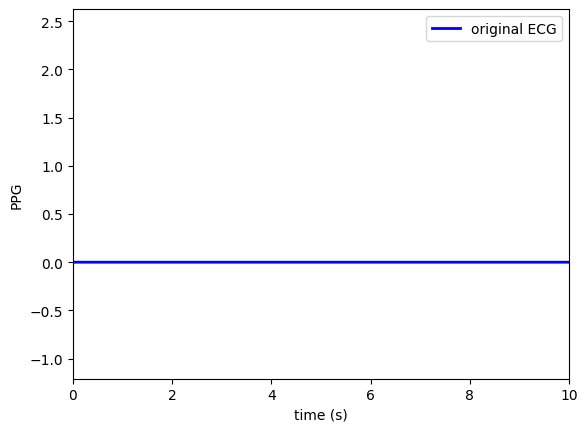

In [26]:
segment_metadata = wfdb.rdheader(record_name=f'{record_name}', pn_dir=record_dir)

print(f"""Header metadata loaded for: 
- the segment '{record_name}'
- for subject '{str(Path(record_dir).parent)}'
""")

print(f"This segment contains the following signals: {segment_metadata.sig_name}")
print(f"The signals are measured in units of: {segment_metadata.units}")
print(f"The signals have a base sampling frequency of {segment_metadata.fs:.1f} Hz")
print(f"and they last for {segment_metadata.sig_len/(segment_metadata.fs*60):.1f} minutes")

# time since the start of the segment at which to begin extracting data
start_seconds = 0
n_seconds_to_load = 10

fs = round(segment_metadata.fs)
sampfrom = fs*start_seconds
sampto = fs*(start_seconds + n_seconds_to_load)

segment_data = wfdb.rdrecord(record_name=f'{record_name}',
                            #  sampfrom=sampfrom,
                            #  sampto=sampto,
                             pn_dir=record_dir)

for sig_no in range(0, len(segment_data.sig_name)):
    if "II" in segment_data.sig_name[sig_no]:
        break

ecg = segment_data.p_signal[:,sig_no]
fs = segment_data.fs
print(f"Extracted the PPG signal from column {sig_no} of the matrix of waveform data.")

fig, ax = plt.subplots()
t = np.arange(0, len(ecg))/segment_data.fs

ax.plot(t, ecg,
        linewidth=2.0,
        color = 'blue',
        label = "original ECG")

ax.set(xlim=(0, n_seconds_to_load))
plt.xlabel('time (s)')
plt.ylabel('PPG')
# plt.xlim([20, 22])
plt.ylim([min(ecg)-0.5, max(ecg)+0.5])

plt.legend()
plt.show()

In [ ]:
example_seg = Path(pd.read_csv('data/matching_records_mimic3.csv')['path'][19])
segment_metadata = wfdb.rdheader(example_seg.name, pn_dir=f'{database_name}/{example_seg.parent}'.replace('\\', '/'))
start_seconds = 55
n_seconds_to_load = 5

fs = round(segment_metadata.fs)
sampfrom = fs*start_seconds
sampto = fs*(start_seconds + n_seconds_to_load)

plot_example = wfdb.rdrecord(record_name=example_seg.name,
                             sampfrom=sampfrom,
                             sampto=sampto,
                             pn_dir=f'{database_name}/{example_seg.parent}'.replace('\\', '/'))

for sig_no in range(0, len(plot_example.sig_name)):
    if "Pleth" in plot_example.sig_name[sig_no]:
        ppg_sig_no = sig_no
    if "ABP" in plot_example.sig_name[sig_no]:
        abp_sig_no = sig_no
    if "II" in plot_example.sig_name[sig_no]:
        ecg_sig_no = sig_no

fs = plot_example.fs
ppg = plot_example.p_signal[:, ppg_sig_no]
abp = plot_example.p_signal[:, abp_sig_no]
ecg = plot_example.p_signal[:, ecg_sig_no]

# signals, info = nk.ecg_process(ecg, sampling_rate=fs, method='pantompkins1985')
# ecg_peaks = signals["ECG_R_Peaks"]

# nk.ecg_plot(signals, info)

ecg_peak_indices = sleepecg.detect_heartbeats(ecg, fs=fs)

# signals, info = nk.ppg_process(ppg, sampling_rate=fs)
# ppg_peaks = signals["PPG_Peaks"]

# nk.ppg_plot(signals, info)
ppg_peak_indices = sleepecg.detect_heartbeats(ppg, fs=fs)

# signals, info = nk.ppg_process(abp, sampling_rate=fs)
# abp_peaks = signals["PPG_Peaks"]

# nk.ppg_plot(signals, info)
abp_peak_indices = sleepecg.detect_heartbeats(abp, fs=fs)

# signals, info = nk.ppg_process(-abp, sampling_rate=fs)
# abp_valleys = signals["PPG_Peaks"]
abp_valley_indices = sleepecg.detect_heartbeats(-abp, fs=fs)

# ecg_peak_indices = np.where(ecg_peaks == 1)[0]
# ppg_peak_indices = np.where(ppg_peaks == 1)[0]
# abp_peak_indices = np.where(abp_peaks == 1)[0]
# abp_valley_indices = np.where(abp_valleys == 1)[0]

t = np.arange(0, len(ppg)) / plot_example.fs

search_radius = int(0.3 * fs)

def correct_peaks(signal, peak_inds, search_radius):	
	corrected_peak_inds = []
    
	for peak in peak_inds:
		# Define the search range, ensuring it stays within the signal bounds
		start = max(peak - search_radius, 0)
		end = min(peak + search_radius, len(signal) - 1)

		# Find the index of the maximum value within the search range
		max_peak_in_range = np.argmax(signal[start:end + 1])  # +1 because of the inclusive end index
		corrected_peak_inds.append(start + max_peak_in_range)
    
	return np.array(corrected_peak_inds)

# Correct the ECG peaks
corrected_ecg_peaks = correct_peaks(ecg, ecg_peak_indices, search_radius)

# Correct the PPG peaks
corrected_ppg_peaks = correct_peaks(ppg, ppg_peak_indices, search_radius)

# Correct the ABP peaks
corrected_abp_peaks = correct_peaks(abp, abp_peak_indices, search_radius)

corrected_abp_valleys = correct_peaks(-abp, abp_valley_indices, search_radius)


# Create the plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle(f'Corrected ECG, PPG, and ABP Signals of {example_seg.name}')

# Plot ECG signal and corrected peaks
ax1.plot(t, ecg, linewidth=2.0, color='red')
ax1.plot(t[corrected_ecg_peaks], ecg[corrected_ecg_peaks], "x", label='Corrected ECG Peaks', color='black')
ax1.set_ylabel('ECG')
ax1.set_ylim([-0.5, 0.5])
ax1.grid(True)
ax1.legend()

# Plot PPG signal and corrected peaks
ax2.plot(t, ppg, linewidth=2.0, color='blue')
ax2.plot(t[corrected_ppg_peaks], ppg[corrected_ppg_peaks], "x", label='Corrected PPG Peaks', color='black')
ax2.set_ylabel('PPG')
ax2.grid(True)
ax2.legend()

# Plot ABP signal with corrected peaks and valleys
ax3.plot(t, abp, linewidth=2.0, color='green')
# Plot the corrected ABP peaks
ax3.plot(t[corrected_abp_peaks], abp[corrected_abp_peaks], "x", label='Corrected ABP Peaks', color='black')
# Plot the corrected ABP valleys
ax3.plot(t[corrected_abp_valleys], abp[corrected_abp_valleys], "o", label='Corrected ABP Valleys', color='blue')  
ax3.set_ylabel('ABP')
ax3.grid(True)
ax3.legend()

# Set shared x-axis label
plt.xlabel('Time (s)')

# Display the plot
plt.show()
